# Exploring the Database of British and Irish Hills

This notebook gives an overview of functions we can work with to explore and manipulate hills data.

In [3]:
import pandas as pd
from zipfile import ZipFile
import io

In [4]:
import hills

ModuleNotFoundError: No module named 'hills'

In [5]:
import matplotlib.pyplot as plt

In [6]:
# The hillsxls.zip file contains a single excel file which we want to read into a pandas dataframe
# We don't necessarily know the name of this file in advance as it's formated based on the database version.
with ZipFile('hillxls.zip') as z:
    excel_filename = z.namelist()[0]
    with z.open(excel_filename) as f:
        df = pd.read_excel(f)

In [7]:
munros = df[df["M"] == 1]

In [8]:
munros[["Name", "Metres", "Col height", "Revision", "M"]]

,Name,Metres,Col height,Revision,M
0,Ben Chonzie,930.4,283.4,2023-07-11,1
16,Ben Vorlich,985.3,151.0,2021-07-11,1
17,Stuc a' Chroin,973.0,720.9,2025-08-20,1
25,Ben More,1173.9,188.0,2024-12-15,1
26,Stob Binnein,1164.8,860.4,2024-12-15,1
...,...,...,...,...,...
1254,Blabheinn [Bla Bheinn],928.8,70.0,2023-03-29,1
1257,Sgurr nan Eag,926.3,796.0,2020-03-31,1
1258,Sgurr a' Mhadaidh,918.0,845.1,2024-01-27,1
1300,Ben More,966.0,0.0,2001-10-28,1


Text(0.5, 1.0, 'Distribution of Munro Col Heights')

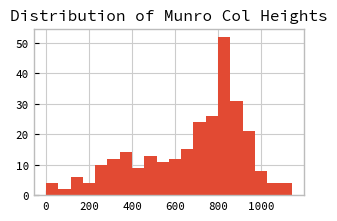

In [9]:
plt.hist(munros["Col height"], bins=20)
plt.title("Distribution of Munro Col Heights")

Text(0.5, 1.0, 'Distribution of Munro Heights')

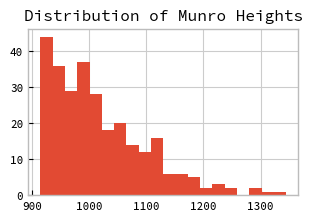

In [10]:
plt.hist(munros["Metres"], bins=20)
plt.title("Distribution of Munro Heights")

In [18]:
!cp /mnt/c/Users/Daniel/Downloads/munrotab_v8.0.1.csv .

In [21]:
munro_changes = pd.read_csv("munrotab_v8.0.1.csv")

In [37]:
changes = munro_changes[['Name',  'DoBIH Number','1891', '1921', '1933', '1953', '1969', '1974', '1981', '1984', '1990',
       '1997', '2021']]

changes[['1891', '1921', '1933', '1953', '1969', '1974', '1981', '1984', '1990',
       '1997', '2021']]

,1891,1921,1933,1953,1969,1974,1981,1984,1990,1997,2021
0,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN
1,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN
2,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN
3,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN
4,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN
...,...,...,...,...,...,...,...,...,...,...,...
598,TOP,TOP,TOP,TOP,TOP,TOP,TOP,TOP,TOP,TOP,TOP
599,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN
600,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN
601,TOP,NaN,NaN,NaN,NaN,NaN,TOP,TOP,TOP,TOP,TOP


In [38]:
# Identify rows where values changed across the year columns
year_columns = ['1891', '1921', '1933', '1953', '1969', '1974', '1981', '1984', '1990', '1997', '2021']

# Function to check if a row has any changes
def has_changes(row):
    """Check if values change at some point in the row."""
    values = row[year_columns]
    # Get unique non-null values
    unique_values = values.dropna().unique()
    
    # Check for changes:
    # 1. If there are multiple non-null unique values
    if len(unique_values) > 1:
        return True
    # 2. If there's at least one NaN and at least one non-NaN value (transition to/from NaN)
    if values.isna().any() and values.notna().any():
        return True
    return False

# Apply the function to find rows with changes
rows_with_changes = munro_changes[munro_changes.apply(has_changes, axis=1)]

print(f"Found {len(rows_with_changes)} rows with changes")
rows_with_changes[['Name', 'DoBIH Number'] + year_columns]

Found 204 rows with changes


,Name,DoBIH Number,1891,1921,1933,1953,1969,1974,1981,1984,1990,1997,2021
7,Stob Binnein - Creag a' Bhragit,39,TOP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Cruach Ardrain,30,MUN,NaN,NaN,NaN,NaN,NaN,MUN,MUN,MUN,MUN,MUN
10,Cruach Ardrain SW Top,29,TOP,MUN,MUN,MUN,MUN,MUN,NaN,NaN,NaN,NaN,NaN
11,Cruach Ardrain - Stob Garbh SE Top,40,TOP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15,Beinn a' Chroin,2925,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,MUN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
590,Sgurr na Banachdich - Sgurr Thormaid,1256,NaN,TOP,TOP,TOP,TOP,TOP,TOP,TOP,TOP,TOP,TOP
591,Sgurr Dearg - Inaccessible Pinnacle,1240,TOP,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN
592,Sgurr Dearg - Cairn,1241,MUN,TOP,TOP,TOP,TOP,TOP,TOP,TOP,TOP,NaN,NaN
593,Sgurr Mhic Choinnich,1248,NaN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN


In [85]:
rows_with_changes[rows_with_changes['Name'] == 'Beinn Achaladair']

,Running No,DoBIH Number,Streetmap,Geograph,Hill-bagging,Name,SMC Section,RHB Section,Height (m),Height\r\n(ft),...,1933,1953,1969,1974,1981,1984,1990,1997,2021,Comments


In [39]:
# Analyze types of changes
def analyze_changes(row):
    """Analyze what type of changes occurred in a row."""
    values = row[year_columns]
    changes_list = []
    
    for i in range(len(values) - 1):
        current = values.iloc[i]
        next_val = values.iloc[i + 1]
        
        if pd.isna(current) and pd.isna(next_val):
            continue
        elif pd.isna(current) and pd.notna(next_val):
            changes_list.append(f"{year_columns[i]} NaN→{next_val}")
        elif pd.notna(current) and pd.isna(next_val):
            changes_list.append(f"{year_columns[i]} {current}→NaN")
        elif current != next_val:
            changes_list.append(f"{year_columns[i]} {current}→{next_val}")
    
    return '; '.join(changes_list) if changes_list else 'No changes'

# Add a column showing the changes
rows_with_changes_detailed = rows_with_changes.copy()
rows_with_changes_detailed['Changes'] = rows_with_changes_detailed.apply(analyze_changes, axis=1)

# Display the detailed results
rows_with_changes_detailed[['Name', 'DoBIH Number', 'Changes']]

,Name,DoBIH Number,Changes
7,Stob Binnein - Creag a' Bhragit,39,1891 TOP→NaN
9,Cruach Ardrain,30,1891 MUN→NaN; 1974 NaN→MUN
10,Cruach Ardrain SW Top,29,1891 TOP→MUN; 1974 MUN→NaN
11,Cruach Ardrain - Stob Garbh SE Top,40,1891 TOP→NaN
15,Beinn a' Chroin,2925,1997 NaN→MUN
...,...,...,...
590,Sgurr na Banachdich - Sgurr Thormaid,1256,1891 NaN→TOP
591,Sgurr Dearg - Inaccessible Pinnacle,1240,1891 TOP→MUN
592,Sgurr Dearg - Cairn,1241,1891 MUN→TOP; 1990 TOP→NaN
593,Sgurr Mhic Choinnich,1248,1891 NaN→MUN


In [40]:
# Count different types of transitions
transition_types = {
    'MUN→TOP': 0,
    'TOP→MUN': 0,
    'MUN→NaN': 0,
    'TOP→NaN': 0,
    'NaN→MUN': 0,
    'NaN→TOP': 0,
    'Other': 0
}

for _, row in rows_with_changes.iterrows():
    values = row[year_columns]
    for i in range(len(values) - 1):
        current = values.iloc[i]
        next_val = values.iloc[i + 1]
        
        if pd.isna(current) and pd.isna(next_val):
            continue
        elif current == 'MUN' and next_val == 'TOP':
            transition_types['MUN→TOP'] += 1
        elif current == 'TOP' and next_val == 'MUN':
            transition_types['TOP→MUN'] += 1
        elif current == 'MUN' and pd.isna(next_val):
            transition_types['MUN→NaN'] += 1
        elif current == 'TOP' and pd.isna(next_val):
            transition_types['TOP→NaN'] += 1
        elif pd.isna(current) and next_val == 'MUN':
            transition_types['NaN→MUN'] += 1
        elif pd.isna(current) and next_val == 'TOP':
            transition_types['NaN→TOP'] += 1
        elif current != next_val:
            transition_types['Other'] += 1

print("Transition type counts:")
for transition, count in sorted(transition_types.items(), key=lambda x: -x[1]):
    if count > 0:
        print(f"  {transition}: {count}")

Transition type counts:
  TOP→NaN: 98
  NaN→TOP: 64
  MUN→TOP: 35
  TOP→MUN: 30
  NaN→MUN: 25
  MUN→NaN: 21
  Other: 2


In [41]:
# Identify hills that were reclassified down (MUN → TOP/NaN) or up (TOP/NaN → MUN)
def get_reclassification_type(row):
    """Determine if a hill was reclassified up, down, or both."""
    values = row[year_columns]
    
    had_mun = False
    had_non_mun = False
    transitions = []
    
    for i in range(len(values) - 1):
        current = values.iloc[i]
        next_val = values.iloc[i + 1]
        
        if current == next_val or (pd.isna(current) and pd.isna(next_val)):
            continue
            
        # Track if we've seen MUN and non-MUN states
        if current == 'MUN':
            had_mun = True
        if current in ['TOP'] or pd.isna(current):
            had_non_mun = True
        if next_val == 'MUN':
            had_mun = True
        if next_val in ['TOP'] or pd.isna(next_val):
            had_non_mun = True
            
        # Reclassified down: MUN → something else
        if current == 'MUN' and next_val != 'MUN':
            transitions.append('down')
        # Reclassified up: something else → MUN
        elif current != 'MUN' and next_val == 'MUN':
            transitions.append('up')
    
    if 'down' in transitions and 'up' in transitions:
        return 'both'
    elif 'down' in transitions:
        return 'down'
    elif 'up' in transitions:
        return 'up'
    else:
        return None

# Apply the function
reclassification_types = rows_with_changes.copy()
reclassification_types['reclass_type'] = reclassification_types.apply(get_reclassification_type, axis=1)

# Separate into down and up
reclass_down = reclassification_types[reclassification_types['reclass_type'].isin(['down', 'both'])]
reclass_up = reclassification_types[reclassification_types['reclass_type'].isin(['up', 'both'])]

print(f"Hills reclassified DOWN (MUN → TOP/NaN): {len(reclass_down)}")
print(f"Hills reclassified UP (TOP/NaN → MUN): {len(reclass_up)}")
print(f"\nHills with both up and down reclassifications: {len(reclassification_types[reclassification_types['reclass_type'] == 'both'])}")

# Display the reclassified hills
print("\n--- Reclassified DOWN ---")
display(reclass_down[['Name', 'DoBIH Number'] + year_columns])

print("\n--- Reclassified UP ---")
display(reclass_up[['Name', 'DoBIH Number'] + year_columns])

Hills reclassified DOWN (MUN → TOP/NaN): 53
Hills reclassified UP (TOP/NaN → MUN): 53

Hills with both up and down reclassifications: 24

--- Reclassified DOWN ---


,Name,DoBIH Number,1891,1921,1933,1953,1969,1974,1981,1984,1990,1997,2021
9,Cruach Ardrain,30,MUN,NaN,NaN,NaN,NaN,NaN,MUN,MUN,MUN,MUN,MUN
10,Cruach Ardrain SW Top,29,TOP,MUN,MUN,MUN,MUN,MUN,NaN,NaN,NaN,NaN,NaN
16,Beinn a' Chroin East Top,36,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,TOP
19,Ben Lui [Beinn Laoigh],65,MUN,MUN,MUN,MUN,MUN,NaN,MUN,MUN,MUN,MUN,MUN
20,Ben Lui NW Top,66,NaN,NaN,NaN,NaN,NaN,MUN,TOP,TOP,TOP,NaN,NaN
29,Beinn an Lochain,1419,MUN,MUN,MUN,MUN,MUN,MUN,NaN,NaN,NaN,NaN,NaN
36,Meall Garbh East Top,119,NaN,NaN,NaN,NaN,NaN,MUN,MUN,NaN,NaN,NaN,NaN
37,Meall Garbh,118,MUN,MUN,MUN,MUN,MUN,NaN,NaN,MUN,MUN,MUN,MUN
53,Beinn Mhanach - Beinn a' Chuirn,126,MUN,TOP,TOP,TOP,TOP,TOP,TOP,TOP,TOP,TOP,TOP
77,Meall Glas - Beinn Cheathaich,161,MUN,TOP,TOP,TOP,TOP,TOP,TOP,TOP,TOP,TOP,TOP



--- Reclassified UP ---


,Name,DoBIH Number,1891,1921,1933,1953,1969,1974,1981,1984,1990,1997,2021
9,Cruach Ardrain,30,MUN,NaN,NaN,NaN,NaN,NaN,MUN,MUN,MUN,MUN,MUN
10,Cruach Ardrain SW Top,29,TOP,MUN,MUN,MUN,MUN,MUN,NaN,NaN,NaN,NaN,NaN
15,Beinn a' Chroin,2925,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,MUN
19,Ben Lui [Beinn Laoigh],65,MUN,MUN,MUN,MUN,MUN,NaN,MUN,MUN,MUN,MUN,MUN
20,Ben Lui NW Top,66,NaN,NaN,NaN,NaN,NaN,MUN,TOP,TOP,TOP,NaN,NaN
36,Meall Garbh East Top,119,NaN,NaN,NaN,NaN,NaN,MUN,MUN,NaN,NaN,NaN,NaN
37,Meall Garbh,118,MUN,MUN,MUN,MUN,MUN,NaN,NaN,MUN,MUN,MUN,MUN
55,An Stuc,142,TOP,TOP,TOP,TOP,TOP,TOP,TOP,TOP,TOP,MUN,MUN
76,Meall Glas,158,TOP,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN
78,Sgiath Chuil,165,TOP,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN,MUN


In [43]:
# Create indices that match positions in the munros DataFrame
# We need to match DoBIH Numbers between the reclassified hills and the munros dataframe

# Get DoBIH Numbers for reclassified hills
reclass_down_dobih = set(reclass_down['DoBIH Number'].values)
reclass_up_dobih = set(reclass_up['DoBIH Number'].values)

# Create a mapping from DoBIH Number to index in munros dataframe
# First check if munros has DoBIH Number column
if 'DoBIH Number' in munros.columns:
    dobih_col = 'DoBIH Number'
elif 'Number' in munros.columns:
    dobih_col = 'Number'
else:
    print("Available columns in munros:", munros.columns.tolist())
    dobih_col = None

if dobih_col:
    # Create indices for PyMC model
    reclassified_down_indices = []
    reclassified_up_indices = []
    
    for idx, row in munros.iterrows():
        dobih_num = row[dobih_col]
        if dobih_num in reclass_down_dobih:
            reclassified_down_indices.append(idx)
        if dobih_num in reclass_up_dobih:
            reclassified_up_indices.append(idx)
    
    print(f"Found {len(reclassified_down_indices)} reclassified DOWN hills in munros dataframe")
    print(f"Found {len(reclassified_up_indices)} reclassified UP hills in munros dataframe")
    print(f"\nIndices ready for PyMC model:")
    print(f"  reclassified_down_indices = {reclassified_down_indices[:10]}{'...' if len(reclassified_down_indices) > 10 else ''}")
    print(f"  reclassified_up_indices = {reclassified_up_indices[:10]}{'...' if len(reclassified_up_indices) > 10 else ''}")
else:
    print("Need to identify the DoBIH Number column in munros dataframe")

Found 10 reclassified DOWN hills in munros dataframe
Found 39 reclassified UP hills in munros dataframe

Indices ready for PyMC model:
  reclassified_down_indices = [29, 64, 117, 311, 383, 385, 522, 889, 926, 1009]
  reclassified_up_indices = [29, 64, 117, 141, 157, 164, 193, 202, 208, 234]...


In [45]:
# Create detailed dataframes for reclassified hills with their munros dataframe index
reclass_down_with_index = reclass_down.copy()
reclass_up_with_index = reclass_up.copy()

# Add munros index column
reclass_down_with_index['munros_index'] = reclass_down_with_index['DoBIH Number'].apply(
    lambda x: munros[munros[dobih_col] == x].index.tolist()[0] if len(munros[munros[dobih_col] == x]) > 0 else None
)

reclass_up_with_index['munros_index'] = reclass_up_with_index['DoBIH Number'].apply(
    lambda x: munros[munros[dobih_col] == x].index.tolist()[0] if len(munros[munros[dobih_col] == x]) > 0 else None
)

# Filter to only those found in munros
reclass_down_matched = reclass_down_with_index[reclass_down_with_index['munros_index'].notna()].copy()
reclass_up_matched = reclass_up_with_index[reclass_up_with_index['munros_index'].notna()].copy()

# Add the changes description from earlier analysis
reclass_down_matched['Changes'] = reclass_down_matched.apply(analyze_changes, axis=1)
reclass_up_matched['Changes'] = reclass_up_matched.apply(analyze_changes, axis=1)

print("Reclassified DOWN hills (matched with munros):")
display(reclass_down_matched[['Name', 'DoBIH Number', 'munros_index', 'Changes']])

print("\nReclassified UP hills (matched with munros):")
display(reclass_up_matched[['Name', 'DoBIH Number', 'munros_index', 'Changes']])

Reclassified DOWN hills (matched with munros):


,Name,DoBIH Number,munros_index,Changes
9,Cruach Ardrain,30,29.0,1891 MUN→NaN; 1974 NaN→MUN
19,Ben Lui [Beinn Laoigh],65,64.0,1969 MUN→NaN; 1974 NaN→MUN
37,Meall Garbh,118,117.0,1969 MUN→NaN; 1981 NaN→MUN
168,An Gearanach,312,311.0,1891 MUN→TOP; 1921 TOP→MUN
205,Sgairneach Mhor,384,383.0,1891 NaN→MUN; 1969 MUN→NaN; 1974 NaN→MUN
207,A' Mharconaich,386,385.0,1969 MUN→NaN; 1974 NaN→MUN
287,Sgor an Lochain Uaine,523,522.0,1891 MUN→TOP; 1990 TOP→MUN
484,Maoile Lunndaidh,890,889.0,1891 MUN→TOP; 1974 TOP→MUN
500,An Riabhachan,927,926.0,1891 MUN→NaN; 1921 NaN→MUN
524,Slioch,1010,1009.0,1933 NaN→MUN; 1974 MUN→TOP; 1990 TOP→MUN



Reclassified UP hills (matched with munros):


,Name,DoBIH Number,munros_index,Changes
9,Cruach Ardrain,30,29.0,1891 MUN→NaN; 1974 NaN→MUN
15,Beinn a' Chroin,2925,2924.0,1997 NaN→MUN
19,Ben Lui [Beinn Laoigh],65,64.0,1969 MUN→NaN; 1974 NaN→MUN
37,Meall Garbh,118,117.0,1969 MUN→NaN; 1981 NaN→MUN
55,An Stuc,142,141.0,1990 TOP→MUN
76,Meall Glas,158,157.0,1891 TOP→MUN
78,Sgiath Chuil,165,164.0,1891 TOP→MUN
86,Stob na Broige (Buachaille Etive Mor),203,202.0,1990 TOP→MUN
89,Stob Coire Raineach (Buachaille Etive Beag),209,208.0,1990 TOP→MUN
93,Stob Coire Sgreamhach,194,193.0,1990 TOP→MUN


In [46]:
# Convert munros dataframe indices to positional indices for the arrays
# The munros dataframe may have non-sequential indices, but arrays need 0-based sequential positions

# Create a mapping from munros dataframe index to array position
munros_index_to_position = {idx: pos for pos, idx in enumerate(munros.index)}

# Convert to positional indices
reclassified_down_indices = [munros_index_to_position[idx] for idx in reclassified_down_indices if idx in munros_index_to_position]
reclassified_up_indices = [munros_index_to_position[idx] for idx in reclassified_up_indices if idx in munros_index_to_position]

print(f"Positional indices for reclassified DOWN: {reclassified_down_indices}")
print(f"Positional indices for reclassified UP: {reclassified_up_indices}")
print(f"\nThese indices can now be used directly with observed_heights array (length {len(observed_heights)})")

Positional indices for reclassified DOWN: [5, 10, 27, 86, 106, 107, 144, 219, 227, 243]
Positional indices for reclassified UP: [5, 10, 27, 32, 42, 44, 48, 55, 57, 60, 82, 86, 106, 107, 110, 123, 124, 144, 164, 165, 167, 183, 190, 204, 206, 219, 227, 231, 233, 235, 240, 243, 245, 246, 269, 274, 276, 279, 281]

These indices can now be used directly with observed_heights array (length 282)


In [29]:
observed_heights = munros['Metres']

In [ ]:
import pymc as pm
import numpy as np

# Use sequential positions already computed for reclassified hills
# Ensure observed heights align with these positions
munros_reset = munros.reset_index(drop=False)  # Keep old index as a column
munros_reset.rename(columns={'index': 'original_index'}, inplace=True)
observed_heights_meters = munros_reset['Metres'].values

# These were already converted to positional indices earlier
reclass_down_positions = reclassified_down_indices
reclass_up_positions = reclassified_up_indices

# Munro threshold in meters (3000 feet = 914.4 meters)
MUNRO_THRESHOLD_METERS = 914.4

with pm.Model() as model:
    # Infer the survey uncertainty from reclassifications
    sigma_survey = pm.HalfNormal('sigma_survey', sigma=20)
    
    # True heights (constrained by classification history)
    true_height = pm.Normal('true_height',
                            mu=observed_heights_meters,
                            sigma=10,  # broad prior equivalent to one contour line interval
                            shape=len(observed_heights_meters))
    
    # Likelihood for observed heights
    obs = pm.Normal('obs', mu=true_height, sigma=sigma_survey,
                    observed=observed_heights_meters)
    
    # For reclassified mountains, use softer constraints with proper PyMC functions
    # Using a soft penalty that encourages but doesn't force the constraints
    for pos in reclass_down_positions:
        # Penalize heights above threshold (reclassified down should be < 914.4m)
        penalty = pm.math.maximum(0, true_height[pos] - MUNRO_THRESHOLD_METERS)
        pm.Potential(f'reclass_down_{pos}', -10 * penalty**2)
    
    for pos in reclass_up_positions:
        # Penalize heights below threshold (reclassified up should be > 914.4m)
        penalty = pm.math.maximum(0, MUNRO_THRESHOLD_METERS - true_height[pos])
        pm.Potential(f'reclass_up_{pos}', -10 * penalty**2)
    
    # Probability of being a Munro
    is_munro = pm.Deterministic('is_munro', true_height > MUNRO_THRESHOLD_METERS)
    
    trace = pm.sample(2000, tune=1000, target_accept=0.9)


Exception ignored on calling ctypes callback function <function ThreadpoolController._find_libraries_with_dl_iterate_phdr.<locals>.match_library_callback at 0x70e4b8b0f6a0>:
Traceback (most recent call last):
  File "/home/daniel/miniconda3/envs/sandbox/lib/python3.13/site-packages/threadpoolctl.py", line 1005, in match_library_callback
    self._make_controller_from_path(filepath)
  File "/home/daniel/miniconda3/envs/sandbox/lib/python3.13/site-packages/threadpoolctl.py", line 1187, in _make_controller_from_path
    lib_controller = controller_class(
  File "/home/daniel/miniconda3/envs/sandbox/lib/python3.13/site-packages/threadpoolctl.py", line 114, in __init__
    self.dynlib = ctypes.CDLL(filepath, mode=_RTLD_NOLOAD)
  File "/home/daniel/miniconda3/envs/sandbox/lib/python3.13/ctypes/__init__.py", line 390, in __init__
    self._handle = _dlopen(self._name, mode)
OSError: dlopen() error
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [s

Output()


:
  File "/home/daniel/miniconda3/envs/sandbox/lib/python3.13/site-packages/threadpoolctl.py", line 1187, in _make_controller_from_path
Traceback (most recent call last):
  File "/home/daniel/miniconda3/envs/sandbox/lib/python3.13/site-packages/threadpoolctl.py", line 1005, in match_library_callback
    Exception ignored on calling ctypes callback function <function ThreadpoolController._find_libraries_with_dl_iterate_phdr.<locals>.match_library_callback at 0x70e54c0b6700>    lib_controller = controller_class(:
self._make_controller_from_path(filepath)
Traceback (most recent call last):

  File "/home/daniel/miniconda3/envs/sandbox/lib/python3.13/site-packages/threadpoolctl.py", line 114, in __init__
  File "/home/daniel/miniconda3/envs/sandbox/lib/python3.13/site-packages/threadpoolctl.py", line 1005, in match_library_callback
  File "/home/daniel/miniconda3/envs/sandbox/lib/python3.13/site-packages/threadpoolctl.py", line 1187, in _make_controller_from_path
            self.dynlib =


OSError: dlopen() error


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 56 seconds.


In [87]:
# Compute posterior probability of being a Munro per hill
# Use ArviZ mean over chains and draws for accuracy
probabilities = trace.posterior['is_munro'].mean(dim=('chain', 'draw')).values

In [93]:
trace.posterior['sigma_survey'].mean()

<xarray.DataArray 'sigma_survey' ()> Size: 8B
array(31.62873409)

In [88]:
# Build probability dataframe
munro_probability = pd.DataFrame({'Name': munros_reset['Name'], 'measured height': munros_reset['Metres'], 'Probability': probabilities})

In [89]:
# Inspect results
pd.set_option("display.max_rows", None)
display(munro_probability.sort_values('Probability', ascending=True))

,Name,measured height,Probability
126,Carn Aosda,915.30,0.530000
107,A' Mharconaich,973.20,0.555875
18,Ben Vane,915.76,0.556750
27,Meall Garbh,967.50,0.557000
243,Slioch,981.20,0.560250
86,An Gearanach,981.50,0.562500
106,Sgairneach Mhor,991.40,0.576125
219,Maoile Lunndaidh,1004.90,0.584500
17,Beinn a' Chleibh,916.30,0.586750
111,Geal-charn,917.10,0.610750


In [95]:
# Diagnostic: check a specific hill
hill = "Mount Keen"
beinn_row = munro_probability[munro_probability['Name'].str.contains(hill, case=False, na=False)]
print(f"{hill} diagnostic:")
display(beinn_row)

# Also show its index and whether it was included in reclass lists
if not beinn_row.empty:
    pos = beinn_row.index[0]
    print(f"Sequential position: {pos}")
    print(f"In reclass_down_positions: {pos in reclass_down_positions}")
    print(f"In reclass_up_positions: {pos in reclass_up_positions}")

Mount Keen diagnostic:


,Name,measured height,Probability
139,Mount Keen,939.4,0.9955


Sequential position: 139
In reclass_down_positions: False
In reclass_up_positions: False


In [96]:
pm.model_to_graphviz(model)

ImportError: This function requires the python library graphviz, along with binaries. The easiest way to install all of this is by running

	conda install -c conda-forge python-graphviz